# kanbior-asr: test the latest checkpoint from Hugging Face

Downloads the latest checkpoint pushed by `02-kaggle_full_finetune.ipynb`, converts it to
CTranslate2 (int8, for faster-whisper on CPU), and tests it on local clips from the **Kaggle test
speakers** (never seen in training).

The HF repo is private: log in once from the activated env with `hf auth login` (a **read** token is enough).

In [5]:
import csv
import random
import re
import sys
import unicodedata
from collections import defaultdict
from pathlib import Path

import jiwer
from ctranslate2.converters import TransformersConverter
from faster_whisper import WhisperModel
from huggingface_hub import snapshot_download
from IPython.display import Audio, display

sys.path.insert(0, ".")
sys.path.insert(0, "../kanbior-mcore")
from fon_text import clean_text, normalize_for_wer
from prepare_data import split_speakers

HUB_REPO = "dyeto/kanbior-fon-asr-v1"
SUBFOLDER = "last-checkpoint"   # "" once training is finished (final model at the repo root)
DATA_DIR = Path("sample-data")
RUNS = Path("runs")

## 1. Download the checkpoint and convert it

In [13]:
import json

download_dir = RUNS / "hub-download"   # overwritten on each download (~1 GB)
prefix = f"{SUBFOLDER}/" if SUBFOLDER else ""
snapshot_download(
    HUB_REPO,
    local_dir=download_dir,
    allow_patterns=[f"{prefix}*"],
    # skip optimizer/scheduler state (~2 GB), only needed to resume training
    ignore_patterns=["*optimizer*", "*scheduler*", "*rng_state*", "*scaler*", "*training_args*"],
)
src = download_dir / SUBFOLDER if SUBFOLDER else download_dir

state_file = src / "trainer_state.json"
if state_file.is_file():
    state = json.loads(state_file.read_text())
    step = state["global_step"]
    evals = [h for h in state["log_history"] if "eval_wer" in h]
    print(f"Checkpoint at step {step:,}. Val WER/CER by step (tones | no tones):")
    for h in evals:
        print(f"  {h['step']:6,}: WER {h['eval_wer']:5.1f} | {h['eval_wer_no_tones']:5.1f}   "
              f"CER {h['eval_cer']:5.1f} | {h['eval_cer_no_tones']:5.1f}")
else:
    step = "final"

ct2_dir = RUNS / f"kanbior-fon-asr-v1-step{step}"
if not (ct2_dir / "model.bin").is_file():
    copy = [f for f in ("tokenizer.json",) if (src / f).is_file()]
    TransformersConverter(str(src), copy_files=copy).convert(str(ct2_dir), quantization="int8", force=True)
print("CTranslate2 model:", ct2_dir)

Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 700.85it/s]

Checkpoint at step 3,000. Val WER/CER by step (tones | no tones):
   1,000: WER  28.3 |  22.8   CER  11.3 |   8.8
   2,000: WER  23.6 |  18.0   CER   9.5 |   7.3
   3,000: WER  21.1 |  15.9   CER   8.4 |   6.4
CTranslate2 model: runs/kanbior-fon-asr-v1-step3000


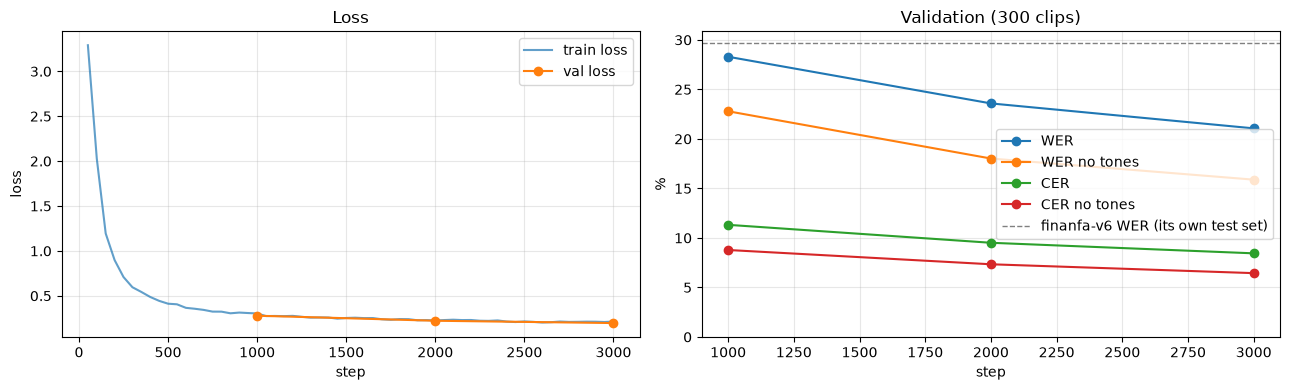

In [14]:
# Training curves from trainer_state.json: train loss every 50 steps, val WER/CER every 1,000 steps.
import matplotlib.pyplot as plt

if state_file.is_file():
    train = [h for h in state["log_history"] if "loss" in h]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot([h["step"] for h in train], [h["loss"] for h in train], label="train loss", alpha=0.7)
    ax1.plot([h["step"] for h in evals], [h["eval_loss"] for h in evals], "o-", label="val loss")
    ax1.set(xlabel="step", ylabel="loss", title="Loss")
    ax1.legend()
    for key, label in [("eval_wer", "WER"), ("eval_wer_no_tones", "WER no tones"),
                       ("eval_cer", "CER"), ("eval_cer_no_tones", "CER no tones")]:
        ax2.plot([h["step"] for h in evals], [h[key] for h in evals], "o-", label=label)
    ax2.axhline(29.7, color="gray", ls="--", lw=1, label="finanfa-v6 WER (its own test set)")
    ax2.set(xlabel="step", ylabel="%", title="Validation (300 clips)", ylim=(0, None))
    ax2.legend()
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [15]:
model = WhisperModel(str(ct2_dir), device="cpu", compute_type="int8")

[2026-11-23 00:11:16.687] [ctranslate2] [thread 2654259] [warning] Tip: experimental MPS backend is available and often 2x+ faster than CPU on Apple Silicon (varies by workload and hardware). Try device="mps".


## 2. Local clips from the Kaggle test speakers

Re-creates the Kaggle speaker split: on Kaggle all audio is present, so the split uses every CSV
row (minus digits/empty), with the same seed as `prepare_data.py`.

In [9]:
with open(DATA_DIR / "transcribed.csv", newline="", encoding="utf-8") as f:
    transcripts = {row["id"]: row for row in csv.DictReader(f)}

by_speaker = defaultdict(list)
for row in transcripts.values():
    if re.search(r"\d", row["transcription"]) or not clean_text(row["transcription"]):
        continue
    by_speaker[row["speaker_id"]].append({"id": row["id"], "duration": float(row["duration"])})
split_of = split_speakers(by_speaker, val_frac=0.1, test_frac=0.1, seed=42, max_eval_speaker_share=0.01)

test_ids = sorted(
    c["id"] for s, cs in by_speaker.items() if split_of[s] == "test" for c in cs
    if (DATA_DIR / transcripts[c["id"]]["audio_path"]).is_file()
)
print(f"{len(test_ids):,} local clips from Kaggle test speakers")

973 local clips from Kaggle test speakers


## 3. Listen and compare

In [16]:
def predict(clip_id):
    path = DATA_DIR / transcripts[clip_id]["audio_path"]
    segments, _ = model.transcribe(str(path), language="fr", beam_size=1)
    return unicodedata.normalize("NFC", " ".join(s.text.strip() for s in segments))

def transcribe(clip_id):
    row = transcripts[clip_id]
    display(Audio(str(DATA_DIR / row["audio_path"])))
    split = split_of.get(row["speaker_id"], "?")
    print(f"Clip:      {clip_id}  ({row['speaker_id']}, {row['duration']} s, Kaggle split: {split})")
    print("Reference:", clean_text(row["transcription"]))
    print("Predicted:", predict(clip_id))

for clip_id in random.Random(0).sample(test_ids, 3):
    transcribe(clip_id)

Clip:      tr_007238  (JML_S199, 5.88 s, Kaggle split: test)
Reference: Axi parakou tɔn ɖokpó sín nukɔn nɛ́. Axi parakou tɔn ɖokpó sín nukɔn wɛ.
Predicted: Axi para kútɔnú ɖokpó sín nukɔn nɛ́. Axi para kútɔnú ɖokpó sín nukɔn wɛ.


Clip:      tr_003315  (JML_S392, 5.94 s, Kaggle split: test)
Reference: Aganma ɖiɖe tɔn ɖíe ɖo ama élɔ lɛ́ɛ mɛ fí e.
Predicted: Agama ɖiɖe tɔn ɖíe ɖo ama élɔ lɛ́ɛ mɛ fí ɛ.


Clip:      tr_006529  (JML_S426, 5.4 s, Kaggle split: test)
Reference: Atín jlɔ́jlɔ́ teví tɔn lɛ́ɛ ɖě ɖo xwé ɔ́ gúdo é.
Predicted: Atín jlɛ́jlɛ́ teví tɔn lɛ́ɛ ɖě ɖo xwé ɔ́ gúdo é.


## 4. WER/CER on N test clips (CPU: ~1–2 s per clip)

In [7]:
N = 50
ids = random.Random(42).sample(test_ids, min(N, len(test_ids)))
refs = [clean_text(transcripts[i]["transcription"]) for i in ids]
hyps = [predict(i) for i in ids]

for keep_tones, label in ((True, "with tones"), (False, "no tones")):
    r = [normalize_for_wer(t, keep_tones) for t in refs]
    h = [normalize_for_wer(t, keep_tones) for t in hyps]
    print(f"{label:10s}: WER {100 * jiwer.wer(r, h):5.1f}%   CER {100 * jiwer.cer(r, h):5.1f}%   ({len(ids)} clips)")

with tones: WER  40.7%   CER  17.0%   (50 clips)
no tones  : WER  33.2%   CER  12.9%   (50 clips)


In [17]:
ids = random.Random(42).sample(test_ids, min(2, len(test_ids)))
transcribe(ids[0])
transcribe(ids[1])

Clip:      tr_005610  (JML_S053, 7.32 s, Kaggle split: test)
Reference: Asyá alɔkpa tɛ́ ká nyí élɔ ɔ́, bɔ sinmɛ alɔkpa atɔ́ɔ́n mɔ̌ wɛ ɖ'é jí. Asyá tɛ́ ká nyí élɔ ɔ́.
Predicted: Asyá alɔkpa tɛ́ntin lɛ́ɛ ɔ́ bɔ sinmɛ alɔkpa atɔ́ɔ́n mɔ̌ ɖe ɖi jí yɛ asyá tɛ́ntin lɛ́ɛ ɔ́.


Clip:      tr_000742  (JML_S210, 6.78 s, Kaggle split: test)
Reference: Boutique lɛ́ɛ nɔ́ nɔ hunhun zǎn kpó kéze kpó nyɔ̌nuzángbe kpódó axɔ́súzángbe kpó.
Predicted: Boutique lɛ́ɛ nɔ́ nɔ hún zǎn gbé kéze kpó nyɔ̌nu zǎn gbé kpó axɔ́súzǎn gbé kpó.
